<a href="https://colab.research.google.com/github/ShinAsakawa/ShinAsakawa.github.io/blob/master/2026notebooks/20261024Binocular_rivalry_2017Li_ported_from_MATLAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
"""NumPy port of Li, Rankin, Rinzel, Carrasco & Heeger (2017) PNAS
attention model of binocular rivalry, following the authors' MATLAB code
(n_model.m / setParameters.m / setStim.m / initTimeSeries.m) line by line.

Purpose here: verification only (does the port reproduce the paper's qualitativeresults?).
Optional OU noise (paper Methods, Noise) is added as a switch.
"""
import numpy as np


def set_parameters(cond, **over):
    p = dict(cond=cond, input=np.array([0.5, 0.5]), dt=0.5, T=15000.0,
             ntheta=2, rect_smooth=True,
             n_m=1, n=2, sigma=0.5, m=2.0, wh=2.0, wo=0.65, wa=0.6,
             tau_s=5.0, tau_o=20.0, tau_a=150.0, tau_h=2000.0,
             sigma_a=0.2, aKernel=np.array([[1., -1.], [-1., 1.]]),
             alpha_t=3.0, alphaAmp=0.5, tan_t=30.0,
             noise_sigma=0.0, noise_tau=100.0, seed=None)
    if cond in (2, 4):
        p['wa'] = 0.0
    if cond == 5:
        p.update(ISP=333.0, blank=150.0)
    if cond == 6:
        p.update(ISP=333.0, blank=0.0)
    if cond == 7:
        p.update(fHz=18.0, sHz=3.0)
    p.update(over)
    p['nt'] = int(round(p['T'] / p['dt'])) + 1
    p['tlist'] = np.arange(p['nt']) * p['dt']
    return p


def _makealpha(dt, T, tau, bound=10e-4):
    t = np.arange(0, T + dt / 2, dt)
    a = t / tau * np.exp(1 - t / tau)
    return a[~((t > tau) & (a < bound))]


def _makeoffset(dt, duration):
    x = np.linspace(np.pi - 1, -np.pi + 0.4, int(round((duration + 2) / dt)))
    o = 0.5 * np.tanh(x) + 0.5
    o = o - o.min()
    o = o / o.max()
    return o[1:-1]


def set_stim(p):
    nt, dt, c = p['nt'], p['dt'], p['cond']
    if c in (1, 2, 3, 4):
        mod = np.ones(nt)
        on = _makealpha(dt, p['alpha_t'] * 100, p['alpha_t'])
        mod[:len(on)] += on * p['alphaAmp']
        oriL, oriR = (np.array([1., 0.]), np.array([0., 1.])) if c in (1, 2) else \
                     (np.array([1., 1.]), np.array([0., 0.]))
        p['stimL'] = np.outer(oriL, mod) * p['input'][0]
        p['stimR'] = np.outer(oriR, mod) * p['input'][1]
    elif c in (5, 6):
        state = (np.floor(p['tlist'] / p['ISP']) % 2).astype(int) + 1
        onsetIdx = np.abs(np.diff(np.r_[0, state]) != 0).astype(float)
        onsetIdx[0] = 1.0
        ts_alpha = np.convolve(onsetIdx, _makealpha(dt, p['alpha_t'] * 100, p['alpha_t']))
        mod = np.ones(nt)
        change = np.where(np.abs(np.diff(np.r_[state[0], state])) > 0)[0]
        nb = int(round(p['blank'] / dt))
        for i in range(1, nb + 1):
            mod[change - i] = 0.0
        offIdx = (np.diff(np.r_[mod[0] + 1, mod]) == -1).astype(float)
        offIdx[0] = 0.0
        ts_off = np.convolve(offIdx, _makeoffset(dt, p['tan_t']))
        mod = mod + ts_alpha[:nt] * p['alphaAmp'] + ts_off[:nt]
        s1, s2 = np.array([1., 0.]), np.array([0., 1.])
        L = np.where(state == 1, s1[:, None], s2[:, None])
        R = np.where(state == 1, s2[:, None], s1[:, None])
        p['stimL'] = L * mod * p['input'][0]
        p['stimR'] = R * mod * p['input'][1]
    elif c == 7:
        non = int(round(1000 / p['fHz'] / dt / 2))
        rep = int(np.ceil(nt / (2 * non)))
        fl = np.tile(np.r_[np.ones(non), np.zeros(non)], rep)[:nt]
        a = _makealpha(dt, p['alpha_t'] * 100, p['alpha_t'])[:non]
        d = np.diff(np.r_[0, fl])
        onIdx = (d == 1).astype(float)
        offIdx = (d == -1).astype(float)
        fl = fl + np.convolve(onIdx, a)[:nt] * p['alphaAmp'] + \
            np.convolve(offIdx, _makeoffset(dt, p['tan_t']))[:nt]
        swapCycle = p['fHz'] / p['sHz']
        state = (np.floor(np.arange(nt) / (swapCycle * non * 2)) % 2).astype(int) + 1
        s1, s2 = np.array([1., 0.]), np.array([0., 1.])
        L = np.where(state == 1, s1[:, None], s2[:, None])
        R = np.where(state == 1, s2[:, None], s1[:, None])
        p['stimL'] = L * fl * p['input'][0]
        p['stimR'] = R * fl * p['input'][1]
    return p


def _rect(x, smooth):
    if not smooth:
        return np.maximum(x, 0.0)
    y = np.zeros_like(x)
    pos = x > 0
    y[pos] = x[pos] / (1 + np.exp(-30 * (x[pos] - 0.05)))
    return y


def run(p):
    rng = np.random.default_rng(p['seed'])
    nt, dt, K = p['nt'], p['dt'], p['ntheta']
    h = lambda x: _rect(x, p['rect_smooth'])
    r = [np.zeros((K, nt)) for _ in range(6)]
    H = [np.zeros((K, nt)) for _ in range(6)]
    o = [np.zeros((K, nt)) for _ in range(2)]
    # initial condition (initTimeSeries.m): one scalar per layer, broadcast
    r[0][:, 0] = rng.random() * 0.2
    r[3][:, 0] = rng.random() * 0.2
    inp_ext = [p['stimL'], p['stimR']]
    # optional OU noise on input drive, independent per eye x orientation
    nz = np.zeros((2, K))
    for k in range(1, nt):
        if p['noise_sigma'] > 0:
            nz += dt / p['noise_tau'] * (-nz) + p['noise_sigma'] * \
                np.sqrt(2 * dt / p['noise_tau']) * rng.standard_normal((2, K))
        d = []
        for lay in (0, 1):
            inp = inp_ext[lay][:, k] + nz[lay]
            d.append(h(np.sign(inp) * np.abs(inp) ** p['n_m'] - o[lay][:, k - 1] * p['wo'])
                     * h(1 + r[5][:, k - 1] * p['wa']))
        S = d[0].sum() + d[1].sum()
        for lay in (0, 1):
            f = p['m'] * d[lay] / (S + p['sigma'] ** p['n_m'] + H[lay][:, k - 1] ** p['n_m'])
            r[lay][:, k] = r[lay][:, k - 1] + dt / p['tau_s'] * (-r[lay][:, k - 1] + f)
            H[lay][:, k] = H[lay][:, k - 1] + dt / p['tau_h'] * (-H[lay][:, k - 1] + r[lay][:, k - 1] * p['wh'])
        # binocular summation & opponency use monocular r at k-1 (as in MATLAB)
        ib = r[0][:, k - 1] + r[1][:, k - 1]
        i4 = h(r[0][:, k - 1] - r[1][:, k - 1])
        i5 = h(r[1][:, k - 1] - r[0][:, k - 1])
        db, d4, d5 = ib ** p['n'], i4 ** p['n'], i5 ** p['n']
        fb = db / (db + p['sigma'] ** p['n'] + H[2][:, k - 1] ** p['n'])
        r[2][:, k] = r[2][:, k - 1] + dt / p['tau_s'] * (-r[2][:, k - 1] + fb)
        H[2][:, k] = H[2][:, k - 1] + dt / p['tau_h'] * (-H[2][:, k - 1] + r[2][:, k] * p['wh'])
        f4 = d4 / (d4.sum() + p['sigma'] ** p['n'])
        f5 = d5 / (d5.sum() + p['sigma'] ** p['n'])
        r[3][:, k] = r[3][:, k - 1] + dt / p['tau_o'] * (-r[3][:, k - 1] + f4)
        r[4][:, k] = r[4][:, k - 1] + dt / p['tau_o'] * (-r[4][:, k - 1] + f5)
        o[1][:, k] = r[3][:, k].sum()   # LE-RE opponency inhibits right eye
        o[0][:, k] = r[4][:, k].sum()   # RE-LE opponency inhibits left eye
        a = p['aKernel'] @ r[2][:, k]
        da = np.sign(a) * np.abs(a) ** p['n']
        sa = (np.abs(a) ** p['n']).sum() + p['sigma_a'] ** p['n']
        r[5][:, k] = r[5][:, k - 1] + dt / p['tau_a'] * (-r[5][:, k - 1] + da / sa)
    p.update(r=r, H=H, o=o)
    return p


def dominance(p, t_skip=1000.0, min_dur=300.0):
    """Dominance epochs from binocular-summation neurons (Rb1 vs Rb2)."""
    rb = p['r'][2]
    keep = p['tlist'] >= t_skip
    s = np.sign(rb[0, keep] - rb[1, keep])
    t = p['tlist'][keep]
    sw = np.where(np.diff(s) != 0)[0]
    edges = np.r_[0, sw + 1, len(s)]
    durs, labs = [], []
    for a, b in zip(edges[:-1], edges[1:]):
        if a < b:
            durs.append(t[b - 1] - t[a] + p['dt'])
            labs.append(s[a])
    durs, labs = np.array(durs), np.array(labs)
    inner = durs[1:-1] if len(durs) > 2 else np.array([])  # drop censored ends
    ci = np.mean(np.abs(rb[0, keep] - rb[1, keep]) / (rb[0, keep] + rb[1, keep] + 1e-12))
    return dict(n_switch=len(sw), durs=inner, labels=labs[1:-1] if len(labs) > 2 else labs,
                competition_index=ci)


cond 1 done
cond 2 done
cond 3 done
cond 4 done
cond 5 done
cond 6 done
cond 7 done
saved: li2017_port_check.png


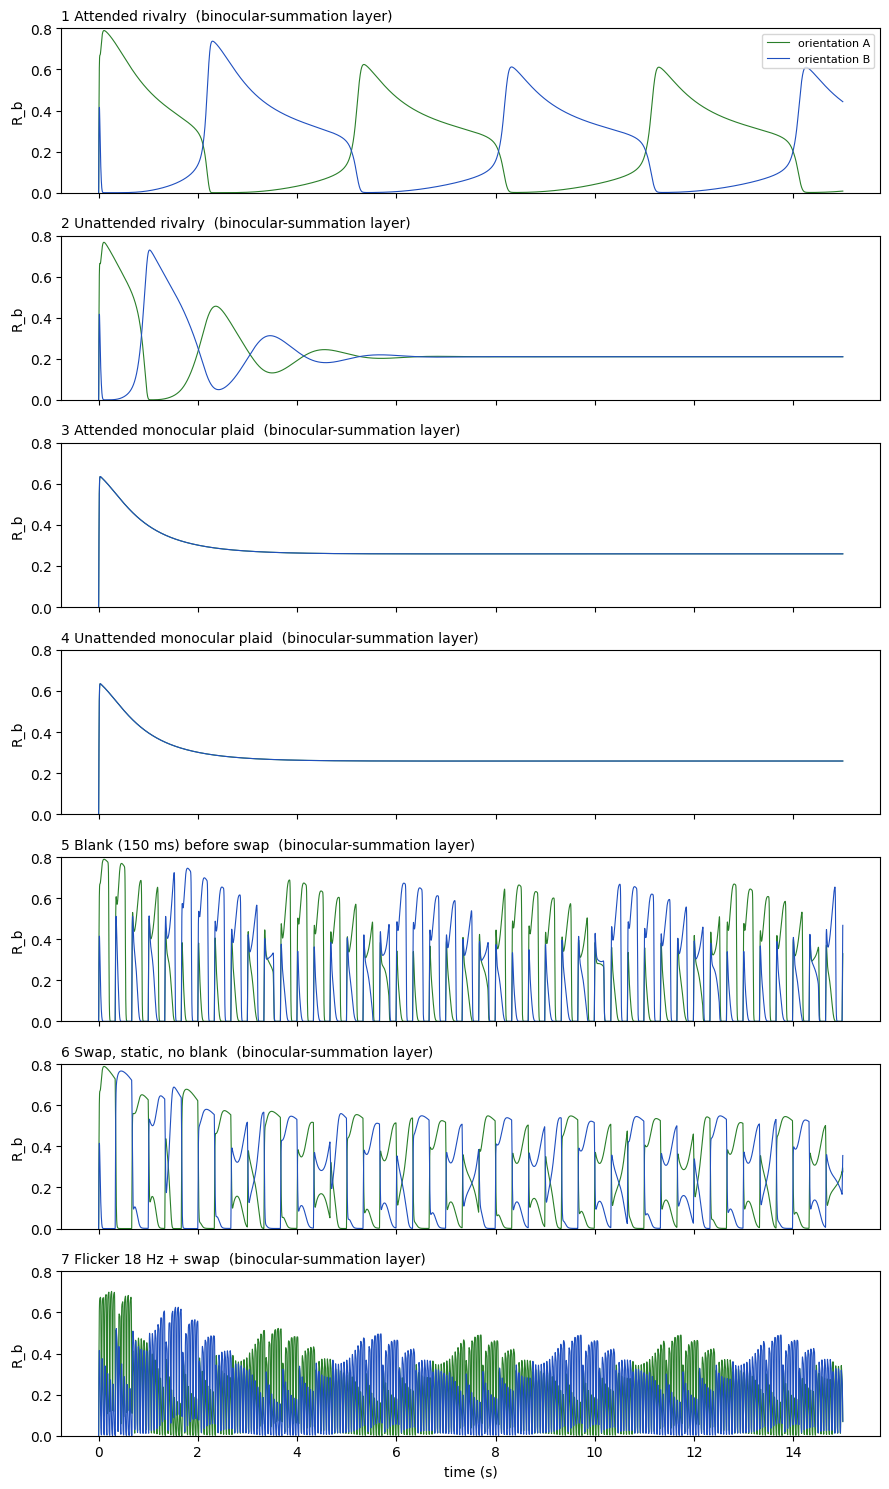

In [2]:
"""Plot the binocular-summation responses of the Li et al. (2017) port for all seven conditions and save them as a PNG.
"""
import matplotlib
import matplotlib.pyplot as plt

TITLES = ['1 Attended rivalry', '2 Unattended rivalry',
          '3 Attended monocular plaid', '4 Unattended monocular plaid',
          '5 Blank (150 ms) before swap', '6 Swap, static, no blank',
          '7 Flicker 18 Hz + swap']


def main(out='li2017_port_check.png', seed=1):
    fig, axes = plt.subplots(7, 1, figsize=(9, 15), sharex=True)
    for ax, cond in zip(axes, range(1, 8)):
        p = run(set_stim(set_parameters(cond, seed=seed)))
        t, rb = p['tlist'] / 1000, p['r'][2]          # layer 3 = binocular summation
        ax.plot(t, rb[0], color='#2a7f2a', lw=0.8, label='orientation A')
        ax.plot(t, rb[1], color='#1f4fbf', lw=0.8, label='orientation B')
        ax.set_title(TITLES[cond - 1] + '  (binocular-summation layer)',
                     fontsize=10, loc='left')
        ax.set_ylim(0, 0.8)
        ax.set_ylabel('R_b')
        print(f'cond {cond} done')
    axes[0].legend(loc='upper right', fontsize=8)
    axes[-1].set_xlabel('time (s)')
    fig.tight_layout()
    fig.savefig(out, dpi=110)
    print('saved:', out)
    if 'inline' in matplotlib.get_backend().lower():
        plt.show()


if __name__ == '__main__':
    main()
